In [1]:
 # Hypothesis test 1, one-way ANOVA
# Question: does mean life expectancy differ across the four GDP quartiles?
# Reads: ../data/clean_joined.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
sns.set_theme(style="whitegrid")

In [3]:
def fmt_p(p):
    # With thousands of rows the p-value is tiny, so report it as "< 0.001"
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

df = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\clean_joined.csv")
order = ["Q1 poorest", "Q2", "Q3", "Q4 richest"]
df["gdp_quartile"] = pd.Categorical(df["gdp_quartile"], categories=order, ordered=True)



In [4]:
# state the hypotheses BEFORE running the test
print("H0: the mean life expectancy is the same in all four GDP quartiles.")
print("H1: at least one GDP quartile has a different mean life expectancy.")
print("Significance level: alpha = 0.05")


H0: the mean life expectancy is the same in all four GDP quartiles.
H1: at least one GDP quartile has a different mean life expectancy.
Significance level: alpha = 0.05


In [5]:
# describe the four groups
summary = df.groupby("gdp_quartile", observed=True)["life_exp"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)
print("\nGROUP SUMMARY")
display(summary)


GROUP SUMMARY


,count,mean,median,std,min,max
gdp_quartile,,,,,,
Q1 poorest,2608,50.14,50.02,8.60,11.30,73.64
Q2,2607,60.41,61.83,8.43,36.44,77.55
Q3,2607,69.01,70.24,5.54,43.96,80.41
Q4 richest,2607,75.55,75.88,4.84,50.65,84.67


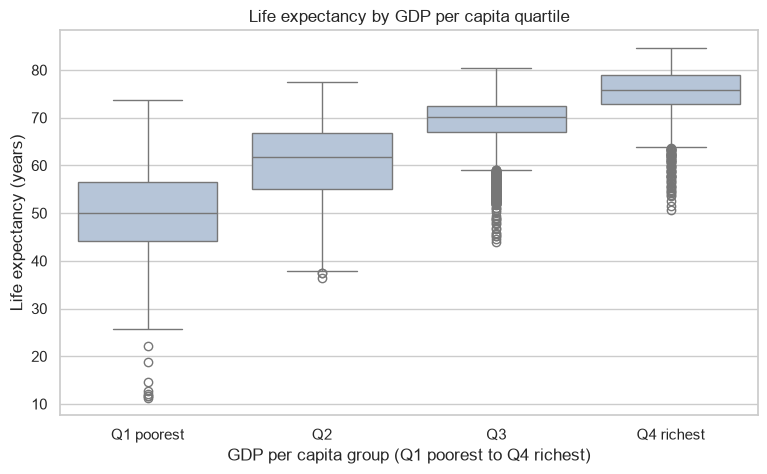

In [6]:
# looking at the groups
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="gdp_quartile", y="life_exp", order=order, color="lightsteelblue")
plt.title("Life expectancy by GDP per capita quartile")
plt.xlabel("GDP per capita group (Q1 poorest to Q4 richest)")
plt.ylabel("Life expectancy (years)")
plt.show()

In [7]:
# check the ANOVA assumptions
groups = [df.loc[df["gdp_quartile"] == q, "life_exp"].values for q in order]

print("\nASSUMPTION CHECKS")
print("Skew in each group (close to 0 means roughly symmetric):")
for q, g in zip(order, groups):
    print(f"  {q}: {pd.Series(g).skew():.2f}")

lev_stat, lev_p = stats.levene(*groups)
print(f"\nLevene test for equal variances: statistic = {lev_stat:.2f}, p {fmt_p(lev_p)}")
print("A small p means the spreads differ between groups, so the plain ANOVA is less trustworthy.")
print("Standard deviations:", summary["std"].to_dict())



ASSUMPTION CHECKS
Skew in each group (close to 0 means roughly symmetric):
  Q1 poorest: -0.18
  Q2: -0.62
  Q3: -1.26
  Q4 richest: -1.02

Levene test for equal variances: statistic = 406.41, p < 0.001
A small p means the spreads differ between groups, so the plain ANOVA is less trustworthy.
Standard deviations: {'Q1 poorest': 8.6, 'Q2': 8.43, 'Q3': 5.54, 'Q4 richest': 4.84}


In [8]:
# runing  the ANOVA
f_stat, p_value = stats.f_oneway(*groups)
print("\nONE WAY ANOVA")
print(f"F statistic = {f_stat:.2f}")
print(f"p-value     = {fmt_p(p_value)}  (SciPy returns {p_value:.1e}, a number too small to be useful)")



ONE WAY ANOVA
F statistic = 6339.31
p-value     = < 0.001  (SciPy returns 0.0e+00, a number too small to be useful)


In [9]:
tukey = pairwise_tukeyhsd(
    endog=df["life_exp"],
    groups=df["gdp_quartile"],
    alpha=0.05
)

print(tukey)

    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1     group2   meandiff p-adj  lower   upper  reject
-----------------------------------------------------------
Q1 poorest         Q2  10.2624   0.0  9.7602 10.7646   True
Q1 poorest         Q3  18.8624   0.0 18.3602 19.3646   True
Q1 poorest Q4 richest  25.4097   0.0 24.9075  25.912   True
        Q2         Q3      8.6   0.0  8.0977  9.1022   True
        Q2 Q4 richest  15.1473   0.0 14.6451 15.6496   True
        Q3 Q4 richest   6.5474   0.0  6.0451  7.0496   True
-----------------------------------------------------------


In [10]:
import pandas as pd
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [11]:
# effect size (how big is the difference, not just is it real)
grand_mean = df["life_exp"].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = ((df["life_exp"] - grand_mean) ** 2).sum()
eta_sq = ss_between / ss_total
print(f"\nEffect size (eta squared) = {eta_sq:.3f}")
print(f"GDP quartile explains about {eta_sq * 100:.0f}% of the variation in life expectancy.")
print("Rough guide: 0.01 small, 0.06 medium, 0.14 large.")



Effect size (eta squared) = 0.646
GDP quartile explains about 65% of the variation in life expectancy.
Rough guide: 0.01 small, 0.06 medium, 0.14 large.


In [12]:
#  a test that does not assume equal spreads
h_stat, kw_p = stats.kruskal(*groups)

print("Kruskal-Wallis H =", round(h_stat, 1))
print("p-value =", "less than 0.001" if kw_p < 0.001 else round(kw_p, 3))

Kruskal-Wallis H = 7198.1
p-value = less than 0.001


In [13]:
#  the same country appears many times, so I take one average per country in each GDP group
country_means = df.groupby(["Entity", "gdp_quartile"], observed=True)["life_exp"].mean().reset_index()

# I put the country averages of each GDP group in its own list
q1 = country_means[country_means["gdp_quartile"] == "Q1 poorest"]["life_exp"]
q2 = country_means[country_means["gdp_quartile"] == "Q2"]["life_exp"]
q3 = country_means[country_means["gdp_quartile"] == "Q3"]["life_exp"]
q4 = country_means[country_means["gdp_quartile"] == "Q4 richest"]["life_exp"]

# I run the ANOVA again on these country averages
f_c, p_c = stats.f_oneway(q1, q2, q3, q4)

print("Countries in each group:", len(q1), len(q2), len(q3), len(q4))
print("F =", round(f_c, 2))
print("p-value =", "less than 0.001" if p_c < 0.001 else round(p_c, 3))

Countries in each group: 68 112 117 81
F = 267.47
p-value = less than 0.001


The spreads differ between quartiles (Levene p < 0.001), so I also ran Kruskal-Wallis (H = 7,198.1, p < 0.001) and repeated the ANOVA on country averages (F = 267.47, p < 0.001). All three agree.

##  One-way ANOVA, life expectancy across GDP quartiles

**H0:** mean life expectancy is the same in all four GDP quartiles.
**H1:** at least one quartile has a different mean life expectancy.
**Test chosen:** one-way ANOVA, because I am comparing the means of a continuous variable across more than two groups.
**Significance level:** alpha = 0.05.

**Result:** F = 6,339.31, p < 0.001. I reject H0 at alpha = 0.05.

**Interpretation:** the average life expectancy differs between GDP quartiles, from about 50 years in the poorest quartile to about 76 in the richest. GDP quartile explains about 65% of the variation (eta squared = 0.646), which is a large effect.

**What the p-value does not mean:** it is not the probability that H0 is true, and it does not measure how big the difference is. It only says the differences would be very unlikely if the true means were equal. The size of the difference comes from the effect size.

**Assumptions and caveats:**
- The spreads differ between quartiles (Levene p < 0.001), so I also ran Kruskal-Wallis (p < 0.001) and a country-average version (p < 0.001). All three agree.
- The same country appears in many years, so rows are not independent. The country-average check reduces this problem.
- The quartiles are based on GDP pooled across all years, so they partly reflect time as well as wealth.
- This shows that the groups differ, not that wealth causes longer life.